# Bank Loan Approval Prediction using Logistic Regression
This notebook implements a Logistic Regression model using scikit-learn's default settings (no penalty or regularisation strength is specified). It prevents data leakage during scaling, removes irrelevant identifiers, one-hot encodes categorical variables, and selects features with explicit correlation rules (weak correlation with the target, or near-duplicate of another feature).

**Outline**
1. Load the dataset
2. Feature correlation analysis (correlation plot, heatmap, selection rules)
3. Pre-processing and feature selection
4. Train / test split and normalisation
5. Functions for training and testing the model
6. Training plots (learning curve, validation loss curve)
7. Evaluation metrics (Confusion Matrix, Accuracy, Precision, Recall, F1, RMSE, ROC AUC)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, precision_score, recall_score,
    f1_score, accuracy_score, mean_squared_error,
    roc_curve, auc, roc_auc_score, classification_report
)

sns.set_theme(style="whitegrid")


## 1. Load the Dataset
The target variable is `Personal.Loan`.

In [2]:
# Load dataset
df = pd.read_csv('../data/bankloan.csv')
display(df.head())
display(df.info())

,ID,Age,Experience,Income,ZIP.Code,Family,CCAvg,Education,Mortgage,Personal.Loan,Securities.Account,CD.Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIP.Code            5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal.Loan       5000 non-null   int64  
 10  Securities.Account  5000 non-null   int64  
 11  CD.Account          5000 non-null   int64  
 12  Online              5000 non-null   int64  
 13  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB


None


## 2. Feature Correlation Analysis
Features are selected with two explicit rules based on the Pearson correlation coefficient:
1. **Weak predictor:** a feature whose absolute correlation with `Personal.Loan` is below `0.05` is dropped.
2. **Redundant feature:** if two features have an absolute correlation above `0.8` with each other, only one of the two is kept.

`ID` and `ZIP.Code` are identifiers (they are dropped in the next section), so they are left out of the correlation plot.

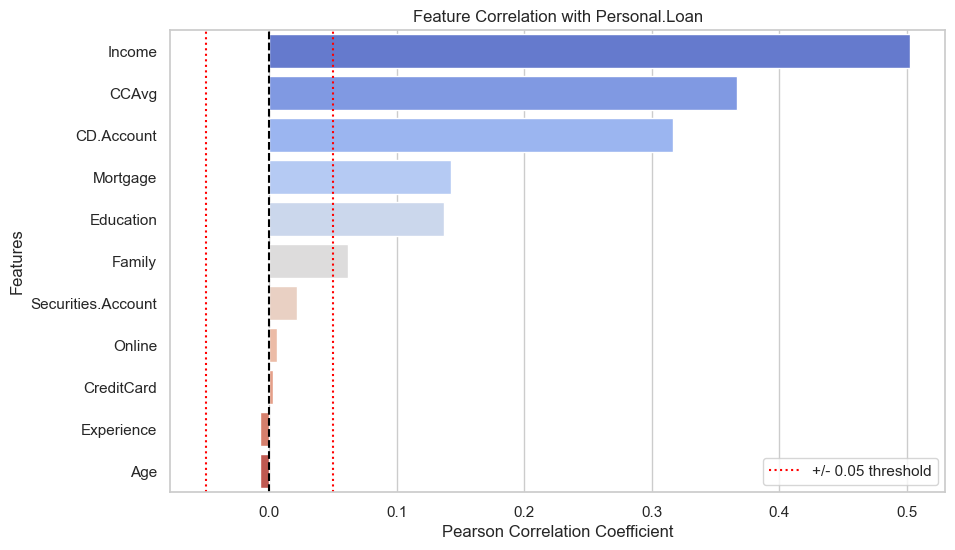

Correlation Values:
 Income                0.502462
CCAvg                 0.366889
CD.Account            0.316355
Mortgage              0.142095
Education             0.136722
Family                0.061367
Securities.Account    0.021954
Online                0.006278
CreditCard            0.002802
Experience           -0.007413
Age                  -0.007726
Name: Personal.Loan, dtype: float64


In [3]:
# Selection thresholds
CORR_THRESHOLD = 0.05        # |correlation with target| below this = weak predictor
COLLINEAR_THRESHOLD = 0.8    # |correlation between two features| above this = redundant pair
identifiers = ['ID', 'ZIP.Code']

# Correlation of every feature with the target (identifiers excluded)
corr_matrix = df.corr(numeric_only=True)
target_corr = corr_matrix['Personal.Loan'].drop(['Personal.Loan'] + identifiers).sort_values(ascending=False)

# Plot the correlations with the selection threshold
plt.figure(figsize=(10, 6))
sns.barplot(x=target_corr.values, y=target_corr.index,hue=target_corr.index, palette='coolwarm')
plt.title("Feature Correlation with Personal.Loan")
plt.xlabel("Pearson Correlation Coefficient")
plt.ylabel("Features")
plt.axvline(x=0, color='black', linestyle='--')
plt.axvline(x=CORR_THRESHOLD, color='red', linestyle=':', label=f'+/- {CORR_THRESHOLD} threshold')
plt.axvline(x=-CORR_THRESHOLD, color='red', linestyle=':')
plt.legend()
plt.show()

print("Correlation Values:\n", target_corr)


### 2.1 Correlation heatmap
The heatmap shows the correlation between every pair of features (identifiers excluded). The bright cell for `Age` and `Experience` is the near-duplicate pair examined by Rule 2 below.

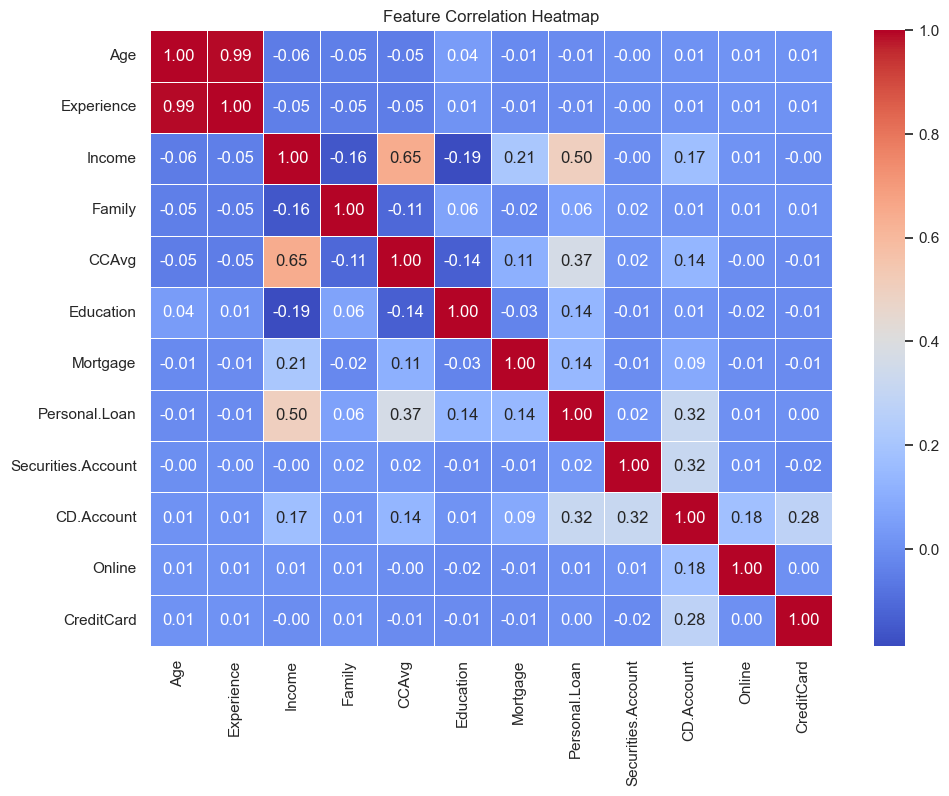

In [4]:
plt.figure(figsize=(11, 8))
sns.heatmap(corr_matrix.drop(index=identifiers, columns=identifiers), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title("Feature Correlation Heatmap")
plt.show()


### 2.2 Rule 1 - weak predictors
A feature whose absolute correlation with `Personal.Loan` is below `0.05` carries almost no linear information about the target, so it is marked for removal.

In [5]:
weak_features = target_corr.index[target_corr.abs() < CORR_THRESHOLD].tolist()
print(f"Rule 1 - weak predictors (|r| < {CORR_THRESHOLD}): {weak_features}")

Rule 1 - weak predictors (|r| < 0.05): ['Securities.Account', 'Online', 'CreditCard', 'Experience', 'Age']



### 2.3 Rule 2 - redundant (near-duplicate) features
If two features have a correlation above `0.8` with each other, they carry almost the same information, so only one of them is kept (the second feature of the pair is dropped). `features_to_drop` then combines Rule 1 and Rule 2.

In [6]:
# Correlation between the features themselves (without the target and the identifiers)
feature_corr = corr_matrix.drop(index=['Personal.Loan'] + identifiers, columns=['Personal.Loan'] + identifiers)

redundant_features = []
cols = feature_corr.columns
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        if abs(feature_corr.iloc[i, j]) > COLLINEAR_THRESHOLD:
            print(cols[i], "and", cols[j], "are highly correlated:", round(feature_corr.iloc[i, j], 3))
            redundant_features.append(cols[j])

features_to_drop = list(set(weak_features + redundant_features))
print("Features to drop:", features_to_drop)

Age and Experience are highly correlated: 0.994
Features to drop: ['Online', 'Securities.Account', 'CreditCard', 'Age', 'Experience']



## 3. Pre-processing and Feature Selection
- **Drop identifiers**: `ID` and `ZIP.Code` are removed.
- **Feature selection**: the weak and redundant features chosen in Section 2 are dropped (`Age`, `Experience`, `Online`, `CreditCard`, `Securities.Account`). `Experience` is a near-duplicate of `Age` (r = 0.994) and all five have |r| < 0.05 with the target.
- **Categorical encoding**: `Education` is one-hot encoded so the model does not assume equal spacing between education levels.

In [7]:
data = df.copy()

# Drop missing targets if any
if 'Personal.Loan' in data.columns:
    data.dropna(subset=['Personal.Loan'], inplace=True)

# Drop row identifiers and location codes
data.drop(columns=['ID', 'ZIP.Code'], errors='ignore', inplace=True)

# Drop the weak / redundant features selected by the correlation rules in Section 2
data.drop(columns=features_to_drop, inplace=True)

# One-hot encode Education to prevent ordinal distance assumptions
if 'Education' in data.columns:
    data = pd.get_dummies(data, columns=['Education'], drop_first=True)

# Fill any remaining missing values
for col in data.columns:
    if data[col].dtype == 'object':
        data[col] = data[col].fillna(data[col].mode()[0])
    else:
        data[col] = data[col].fillna(data[col].median())

# Separate features (X) and target (y)
target_col = 'Personal.Loan'
X = data.drop(columns=[target_col])
y = data[target_col]

print("Selected features:", X.columns.tolist())
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Selected features: ['Income', 'Family', 'CCAvg', 'Mortgage', 'CD.Account', 'Education_2', 'Education_3']
Shape of X: (5000, 7)
Shape of y: (5000,)



## 4. Train / Test Split
80% of the data is used for training and 20% for testing. `stratify=y` keeps the same share of approved loans in both sets. The split happens **before** scaling so no test-set information leaks into training.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training Data Shape: {X_train.shape}")
print(f"Testing Data Shape:  {X_test.shape}")
print(f"Approval rate - train: {y_train.mean():.3%} | test: {y_test.mean():.3%}")

Training Data Shape: (4000, 7)
Testing Data Shape:  (1000, 7)
Approval rate - train: 9.600% | test: 9.600%



### 4.1 Normalisation
`StandardScaler` gives every feature mean 0 and standard deviation 1. It is **fitted on the training data only** and then applied to the test data.

In [9]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

display(X_train_scaled.head())

,Income,Family,CCAvg,Mortgage,CD.Account,Education_2,Education_3
408,0.335098,-0.332080,0.505071,-0.553909,-0.255988,-0.618972,-0.658163
3737,-0.938772,-1.201969,-0.817714,-0.553909,-0.255988,-0.618972,1.519381
3889,-1.176273,-1.201969,-1.047763,0.643609,-0.255988,1.615583,-0.658163
568,-0.701271,-0.332080,-1.047763,1.039483,-0.255988,-0.618972,-0.658163
1041,-0.485361,1.407697,-0.242590,-0.553909,-0.255988,-0.618972,-0.658163



## 5. Functions for Training and Testing the Model
- `train_model()` creates a Logistic Regression model with scikit-learn's default settings (no penalty or regularisation strength is specified) and fits it.
- `evaluate_model()` tests a model on any data set and returns Accuracy, Precision, Recall, F1, RMSE and ROC AUC, together with the predictions and probabilities.


### 5.1 Training function
`make_model()` builds the Logistic Regression model with scikit-learn's default settings; `train_model()` fits it on the data it is given.

In [10]:
def make_model(max_iter=1000):
    """Create a Logistic Regression model (not trained yet)."""
    return LogisticRegression(random_state=42, max_iter=max_iter)


def train_model(X_tr, y_tr, max_iter=1000):
    """Train the model and return it."""
    model = make_model(max_iter)
    model.fit(X_tr, y_tr)
    return model

### 5.2 Train the model
Call `train_model()` on the scaled training data.

In [11]:
model = train_model(X_train_scaled, y_train)
print("Model trained successfully!")

Model trained successfully!


### 5.3 Testing function
`evaluate_model()` tests the model on any data set (training or testing) and returns the metrics, predicted labels and predicted probabilities.

In [12]:
def evaluate_model(model, X_ev, y_ev):
   #Test the model. Returns (metrics dictionary, predicted labels, predicted probabilities)
    y_hat = model.predict(X_ev)
    y_proba = model.predict_proba(X_ev)[:, 1]
    metrics = {
        "Accuracy": accuracy_score(y_ev, y_hat),
        "Precision": precision_score(y_ev, y_hat),
        "Recall": recall_score(y_ev, y_hat),
        "F1 Score": f1_score(y_ev, y_hat),
        "RMSE": np.sqrt(mean_squared_error(y_ev, y_hat)),
        "ROC AUC": roc_auc_score(y_ev, y_proba),
    }
    return metrics, y_hat, y_proba

## 6. Training Plots
### 6.1 Learning curve
`learning_curve()` from scikit-learn trains the model on a growing share of the training data (10% to 100%) with 5-fold cross-validation and returns the **training score** and **validation score** for each size. The scaler is inside a `Pipeline`, so it is re-fitted on the training part of every fold and no information leaks between folds. The score is accuracy (the default). If the two curves meet and level off, more data is unlikely to help much.


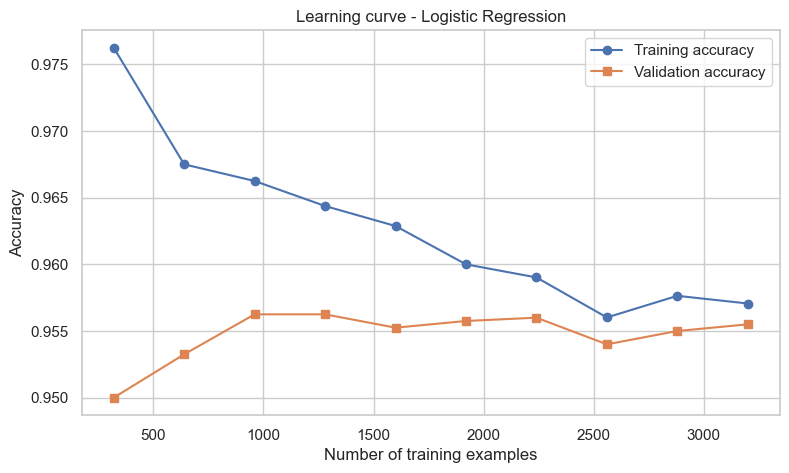

In [13]:
pipe = Pipeline([("scaler", StandardScaler()), ("model", make_model())])
train_sizes = np.linspace(0.1, 1.0, 10)

sizes, train_scores, val_scores = learning_curve(pipe, X_train, y_train, cv=5, train_sizes=train_sizes)

plt.figure(figsize=(9, 5))
plt.plot(sizes, train_scores.mean(axis=1), marker='o', label="Training accuracy")
plt.plot(sizes, val_scores.mean(axis=1), marker='s', label="Validation accuracy")
plt.title("Learning curve - Logistic Regression")
plt.xlabel("Number of training examples")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

### 6.2 Validation loss curve
The same `learning_curve()` with `scoring="neg_log_loss"` gives the **log-loss** (cross-entropy, the quantity logistic regression minimises). A negative sign turns scikit-learn's "negative loss" scores back into losses, so lower is better. If the validation loss stays clearly above the training loss, the model fits the training data better than unseen data.

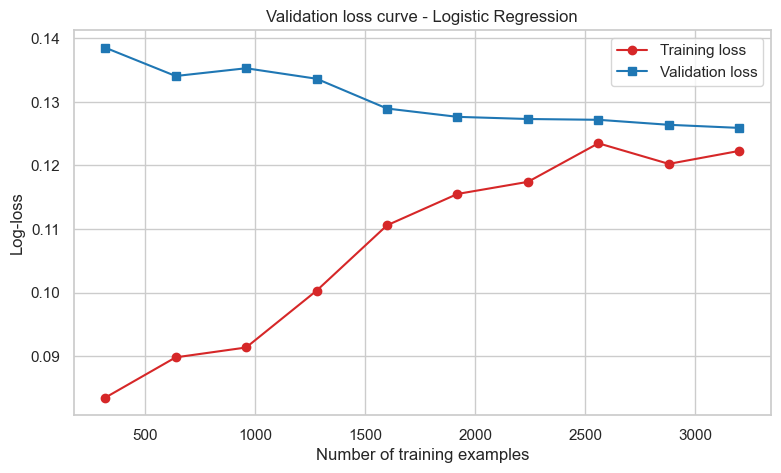

In [14]:
sizes, train_scores, val_scores = learning_curve(pipe, X_train, y_train, cv=5, train_sizes=train_sizes,
                                                  scoring="neg_log_loss")
train_loss = -train_scores.mean(axis=1)
val_loss = -val_scores.mean(axis=1)

plt.figure(figsize=(9, 5))
plt.plot(sizes, train_loss, marker='o', color='tab:red', label="Training loss")
plt.plot(sizes, val_loss, marker='s', color='tab:blue', label="Validation loss")
plt.title("Validation loss curve - Logistic Regression")
plt.xlabel("Number of training examples")
plt.ylabel("Log-loss")
plt.legend()
plt.show()

## 7. Evaluation Metrics
### 7.1 Train vs test metrics

The evaluate_model() function is used on both the training and testing datasets. Similar scores on both datasets indicate that the model is not overfitting.

- Accuracy: Percentage of correct predictions.
- Precision: Of predicted approvals, how many are actually approved.
- Recall: Of actual approvals, how many are correctly identified.
- F1 Score: Harmonic mean of precision and recall.
- RMSE: Root mean squared error; lower is better.
- ROC AUC: Measures how well the model distinguishes approved and rejected customers.

In [ ]:
train_metrics, y_train_pred, _ = evaluate_model(
    model, X_train_scaled, y_train
)

test_metrics, y_pred, y_prob = evaluate_model(
    model, X_test_scaled, y_test
)

display(pd.DataFrame(
    [train_metrics, test_metrics],
    index=["Train", "Test"]
).round(4))

print("--- Test Set Evaluation Metrics ---")

for name, value in test_metrics.items():
    print(f"{name:10s}: {value:.4f}")

### 7.2 Confusion matrix (test set)

A confusion matrix compares actual labels with predicted labels.

- True Negative: Correctly predicted rejection.
- True Positive: Correctly predicted approval.
- False Positive: Predicted approval when the actual result was rejection.
- False Negative: Predicted rejection when the actual result was approval.

In [ ]:
def plot_confusion_matrix(y_true, y_hat, title="Confusion Matrix"):
    """Heat-map of the confusion matrix."""

    cm = confusion_matrix(y_true, y_hat)

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        cbar=False,
        xticklabels=['Rejected', 'Approved'],
        yticklabels=['Rejected', 'Approved']
    )

    plt.title(title)
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.show()

    return cm

In [ ]:
conf_matrix = plot_confusion_matrix(
    y_test, y_pred, "Confusion Matrix - Test Set"
)

TN, FP, FN, TP = conf_matrix.ravel()

print(f"True Negatives : {TN}")
print(f"False Positives: {FP}")
print(f"False Negatives: {FN}")
print(f"True Positives : {TP}")

### 7.3 Classification report

The classification report shows precision, recall and F1 score for each class (Rejected and Approved). It helps us understand how well the model predicts each category.

In [ ]:
print(classification_report(
    y_test,
    y_pred,
    target_names=['Rejected', 'Approved'],
    digits=3
))

### 7.4 ROC curve and coefficients

The ROC curve shows the relationship between the True Positive Rate and False Positive Rate at different classification thresholds. The AUC value measures the model's ability to distinguish between approved and rejected customers.

The coefficient plot shows how different features influence the model's prediction.

In [ ]:
# ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr, tpr,
    color='darkorange',
    lw=2,
    label=f'ROC curve (AUC = {roc_auc:.2f})'
)

plt.plot(
    [0, 1], [0, 1],
    color='navy',
    lw=2,
    linestyle='--'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()


# Logistic Regression coefficients
coefficients = model.coef_[0]
feature_names = X_train_scaled.columns

plt.figure(figsize=(10, 6))

sns.barplot(
    x=coefficients,
    y=feature_names,
    palette='viridis'
)

plt.title("Logistic Regression Coefficients")
plt.xlabel("Coefficient Value")
plt.ylabel("Feature")
plt.show()